image (600, 5, 64, 64) float32
spectrum (600, 7783) float32
specz_redshift (600,) float32
targetid (600,) int64
Images: (5, 5, 64, 64)
Redshifts: (5,)
Spectra: (5, 7783)


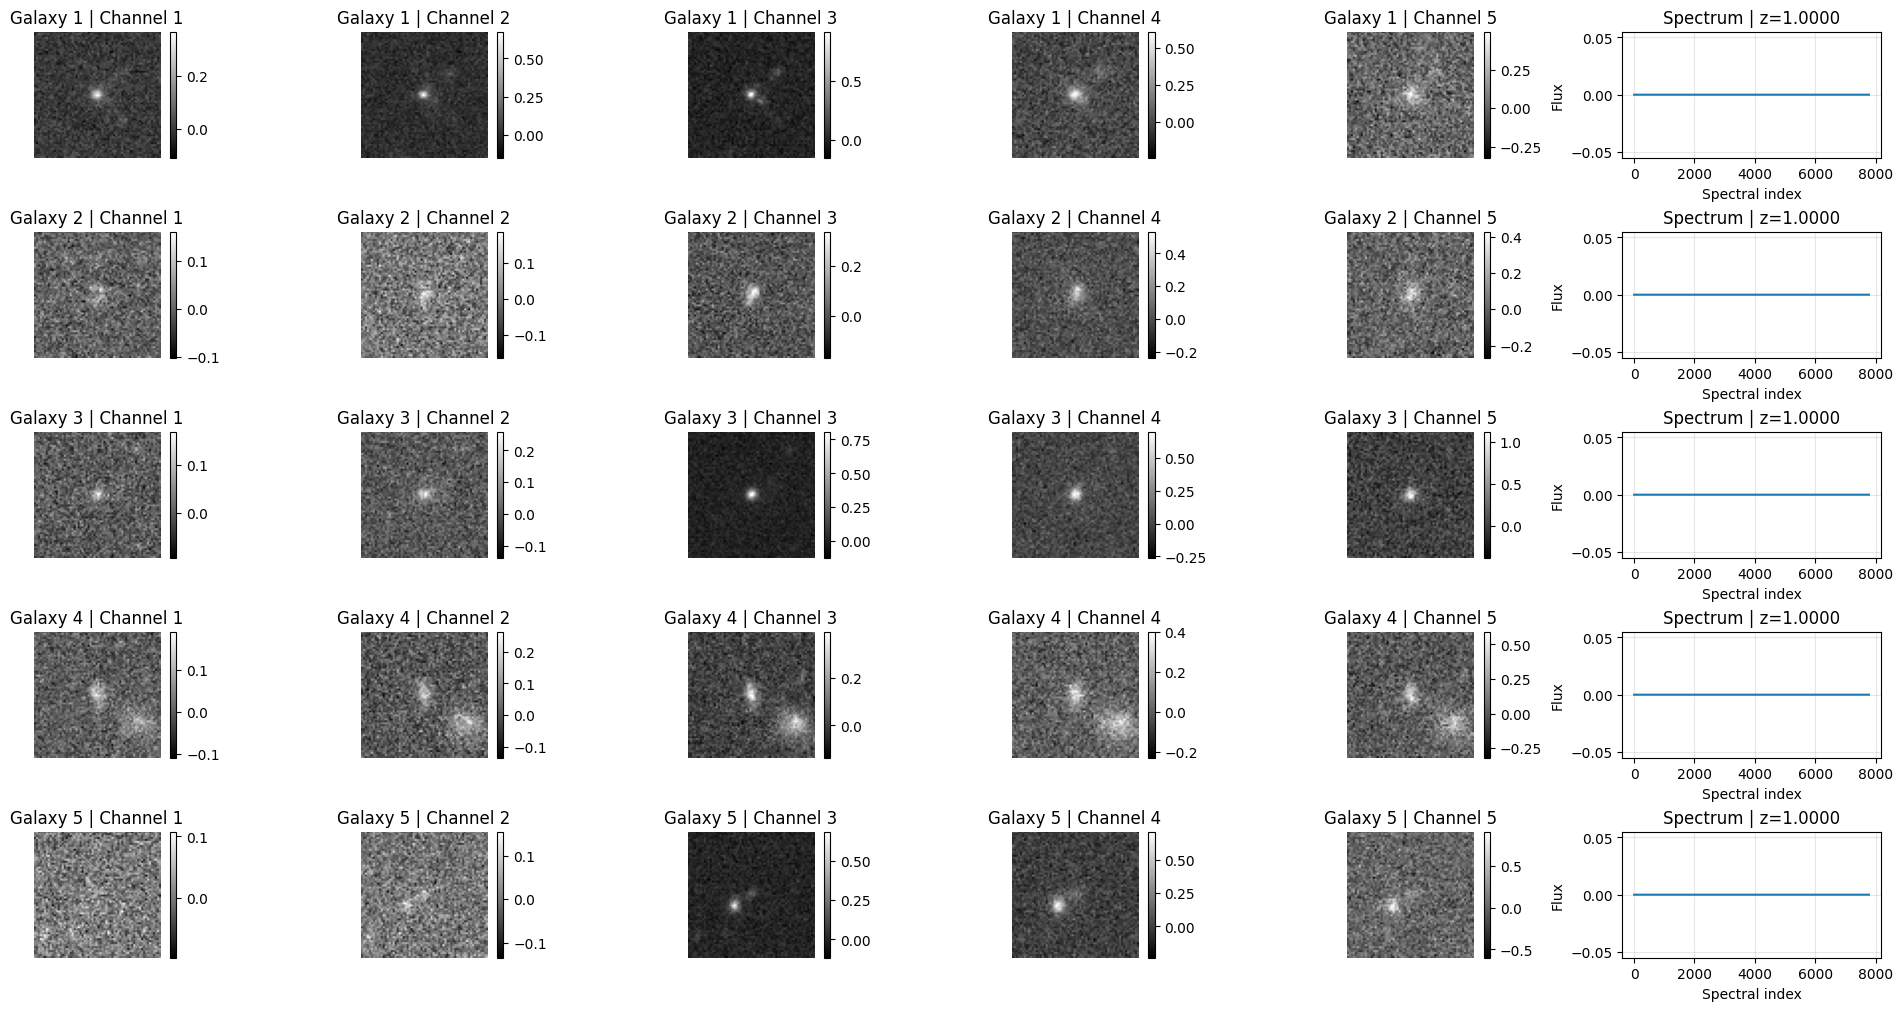

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

file_path = "generated_galaxies_1.hdf5"
k = 5
with h5py.File(file_path, "r") as f:
    # Inspect dataset structure
    for key in f.keys():
        print(key, f[key].shape, f[key].dtype)

    # Select k unique random galaxies. h5py requires sorted indices.
    random_indices = np.random.choice(f["image"].shape[0], size=k, replace=False)
    random_indices.sort()

    images = f["image"][random_indices]
    redshifts = f["specz_redshift"][random_indices]
    spectra = f["spectrum"][random_indices]

print("Images:", images.shape)
print("Redshifts:", redshifts.shape)
print("Spectra:", spectra.shape)

fig, axes = plt.subplots(
    k, 6,
    figsize=(20, 10),
    constrained_layout=True
)

for i in range(k):

    # Display the 5 image channels
    for c in range(5):
        ax = axes[i, c]

        im = ax.imshow(
            images[i, c],
            cmap="gray",
            origin="lower"
        )

        ax.set_title(f"Galaxy {random_indices[i]} | Channel {c+1}")
        ax.axis("off")

        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Display spectrum
    ax = axes[i, 5]

    ax.plot(spectra[i])
    ax.set_title(f"Spectrum | z={redshifts[i]:.4f}")
    ax.set_xlabel("Spectral index")
    ax.set_ylabel("Flux")
    ax.grid(alpha=0.3)

plt.show()

In [3]:
for i in range(3):
    print(f"\nGalaxy {i+1}")
    print(f"Redshift: {redshifts[i]:.4f}")
    print(f"Spectrum all zeros: {np.all(spectra[i] == 0)}")

    for c in range(5):
        channel = images[i, c]

        print(
            f"Channel {c+1}: "
            f"min={channel.min():.5f}, "
            f"max={channel.max():.5f}, "
            f"mean={channel.mean():.5f}, "
            f"std={channel.std():.5f}"
        )


Galaxy 1
Redshift: 0.1000
Spectrum all zeros: True
Channel 1: min=-0.08917, max=1.49241, mean=0.12363, std=0.18636
Channel 2: min=-0.10550, max=3.27034, mean=0.20454, std=0.34488
Channel 3: min=-0.13366, max=4.88335, mean=0.27607, std=0.49483
Channel 4: min=-0.22759, max=5.25011, mean=0.31595, std=0.57251
Channel 5: min=-0.41118, max=7.49600, mean=0.35791, std=0.68924

Galaxy 2
Redshift: 0.2000
Spectrum all zeros: True
Channel 1: min=-0.08200, max=1.47868, mean=0.05905, std=0.15511
Channel 2: min=-0.13081, max=3.37257, mean=0.13926, std=0.34972
Channel 3: min=-0.11241, max=8.63727, mean=0.20095, std=0.61269
Channel 4: min=-0.25696, max=10.57177, mean=0.25620, std=0.77864
Channel 5: min=-0.48317, max=12.42828, mean=0.31867, std=0.90296

Galaxy 3
Redshift: 0.5000
Spectrum all zeros: True
Channel 1: min=-0.09228, max=0.94480, mean=0.00897, std=0.05545
Channel 2: min=-0.13642, max=1.50593, mean=0.01591, std=0.09074
Channel 3: min=-0.12772, max=2.95349, mean=0.01988, std=0.14259
Channel 4: